<a href="https://colab.research.google.com/github/HUALWILL-ia/VISION-COMPUTACIONAL/blob/main/Proyecto_Vision.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Instalar kagglehub (si ya está instalado, no hace nada)
%pip install -q kagglehub

import kagglehub

# Descargar la última versión del dataset (son unos 2 GB, puede tardar unos minutos)
path = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")
print("Ruta de los archivos:", path)

Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.
Ruta de los archivos: /kaggle/input/chest-xray-pneumonia


In [ ]:
import os

# Buscar automáticamente la carpeta que contiene train, test y val
# (evita problemas con la carpeta duplicada y __MACOSX)
base = None
for raiz, carpetas, _ in os.walk(path):
    if {"train", "test", "val"}.issubset(set(carpetas)):
        base = raiz
        break

print("Ruta base:", base)
print(os.listdir(base))


Ruta base: /kaggle/input/chest-xray-pneumonia/chest_xray
['chest_xray', '__MACOSX', 'val', 'test', 'train']


Total de imágenes: 5856


,split,clase,ruta
0,train,NORMAL,/kaggle/input/chest-xray-pneumonia/chest_xray/...
1,train,NORMAL,/kaggle/input/chest-xray-pneumonia/chest_xray/...
2,train,NORMAL,/kaggle/input/chest-xray-pneumonia/chest_xray/...
3,train,NORMAL,/kaggle/input/chest-xray-pneumonia/chest_xray/...
4,train,NORMAL,/kaggle/input/chest-xray-pneumonia/chest_xray/...



Conteo por split y clase:
clase  NORMAL  PNEUMONIA   All
split                         
test      234        390   624
train    1341       3875  5216
val         8          8    16
All      1583       4273  5856

Porcentaje de neumonía por split:
split
test     62.5
train    74.3
val      50.0
All      73.0
dtype: float64


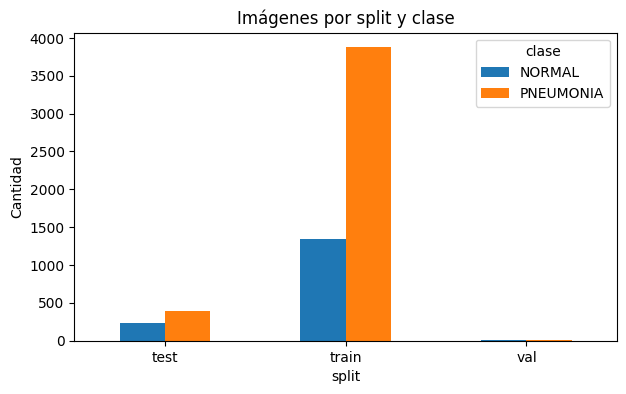

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# Recorrer train, test y val y guardar la ruta de cada imagen con su split y su clase
registros = []
for split in ["train", "test", "val"]:
    for clase in ["NORMAL", "PNEUMONIA"]:
        carpeta = os.path.join(base, split, clase)
        for nombre in os.listdir(carpeta):
            if nombre.lower().endswith((".jpeg", ".jpg", ".png")):
                registros.append({"split": split, "clase": clase,
                                  "ruta": os.path.join(carpeta, nombre)})

df = pd.DataFrame(registros)
print("Total de imágenes:", len(df))
display(df.head())

# Tabla cruzada para ver el desbalance entre clases en cada split
conteo = pd.crosstab(df["split"], df["clase"], margins=True)
print("\nConteo por split y clase:")
print(conteo)

# Proporción de neumonía dentro de cada split
print("\nPorcentaje de neumonía por split:")
print((conteo["PNEUMONIA"] / conteo["All"] * 100).round(1))

# Gráfica de barras (sin la fila ni la columna de totales)
conteo.drop(index="All", columns="All").plot(kind="bar", figsize=(7, 4))
plt.title("Imágenes por split y clase")
plt.ylabel("Cantidad")
plt.xticks(rotation=0)
plt.show()

In [ ]:
# Leer ancho, alto y modo de color de cada imagen (abrir solo lee el encabezado, es rápido)
anchos, altos, modos = [], [], []
for ruta in df["ruta"]:
    with Image.open(ruta) as img:
        anchos.append(img.size[0])
        altos.append(img.size[1])
        modos.append(img.mode)

df["ancho"], df["alto"], df["modo"] = anchos, altos, modos
df["proporcion"] = df["ancho"] / df["alto"]

# Resumen estadístico de tamaños y proporciones
print(df[["ancho", "alto", "proporcion"]].describe())

# Modos de color: ¿hay mezcla de escala de grises (L) y RGB?
print("\nModos de color:\n", df["modo"].value_counts())

# Tamaños por clase, para ver si difieren entre normal y neumonía
print("\nTamaño mediano por clase:")
print(df.groupby("clase")[["ancho", "alto"]].median())


             ancho         alto   proporcion
count  5856.000000  5856.000000  5856.000000
mean   1327.880806   970.689037     1.442986
std     363.500922   383.392117     0.254356
min     384.000000   127.000000     0.835391
25%    1056.000000   688.000000     1.261627
50%    1281.000000   888.000000     1.415885
75%    1560.000000  1187.000000     1.585750
max    2916.000000  2713.000000     3.378788

Modos de color:
 modo
L      5573
RGB     283
Name: count, dtype: int64

Tamaño mediano por clase:
            ancho    alto
clase                    
NORMAL     1654.0  1323.0
PNEUMONIA  1160.0   776.0


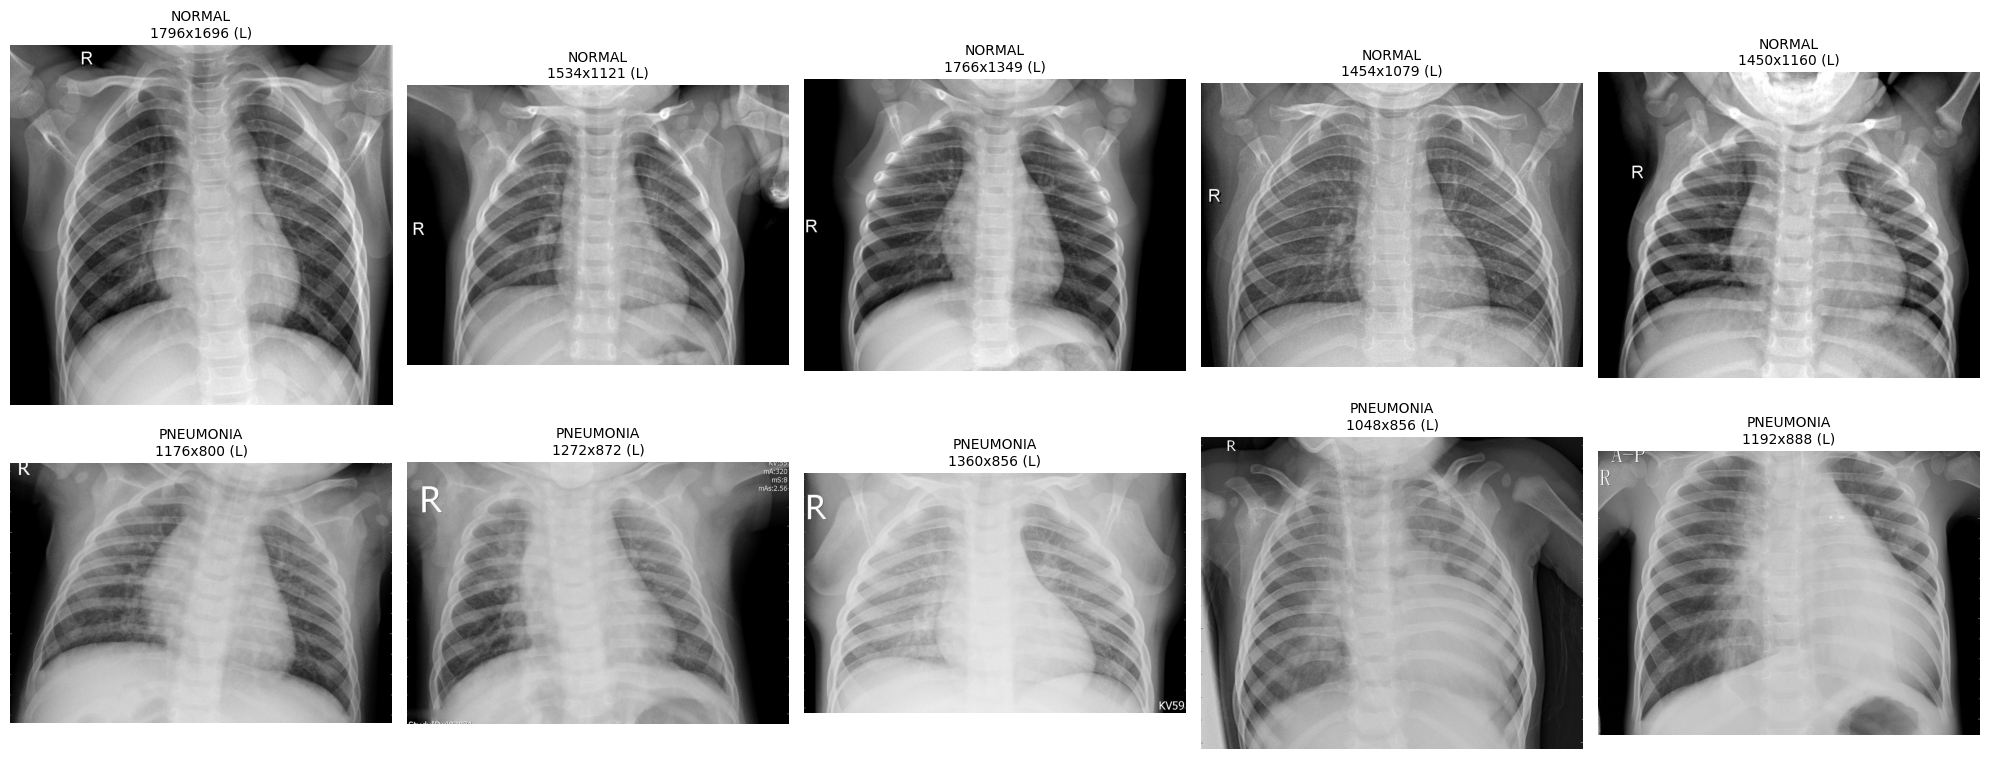

In [ ]:
# Mostrar 5 imágenes aleatorias de cada clase con su tamaño y modo de color
fig, ejes = plt.subplots(2, 5, figsize=(20, 8))

for fila, clase in enumerate(["NORMAL", "PNEUMONIA"]):
    # random_state fijo para que las muestras sean reproducibles
    muestras = df[df["clase"] == clase].sample(5, random_state=42)
    for col, (_, r) in enumerate(muestras.iterrows()):
        img = Image.open(r["ruta"])
        ejes[fila, col].imshow(img, cmap="gray")
        ejes[fila, col].set_title(f"{clase}\n{r['ancho']}x{r['alto']} ({r['modo']})", fontsize=10)
        ejes[fila, col].axis("off")

plt.tight_layout()
plt.show()

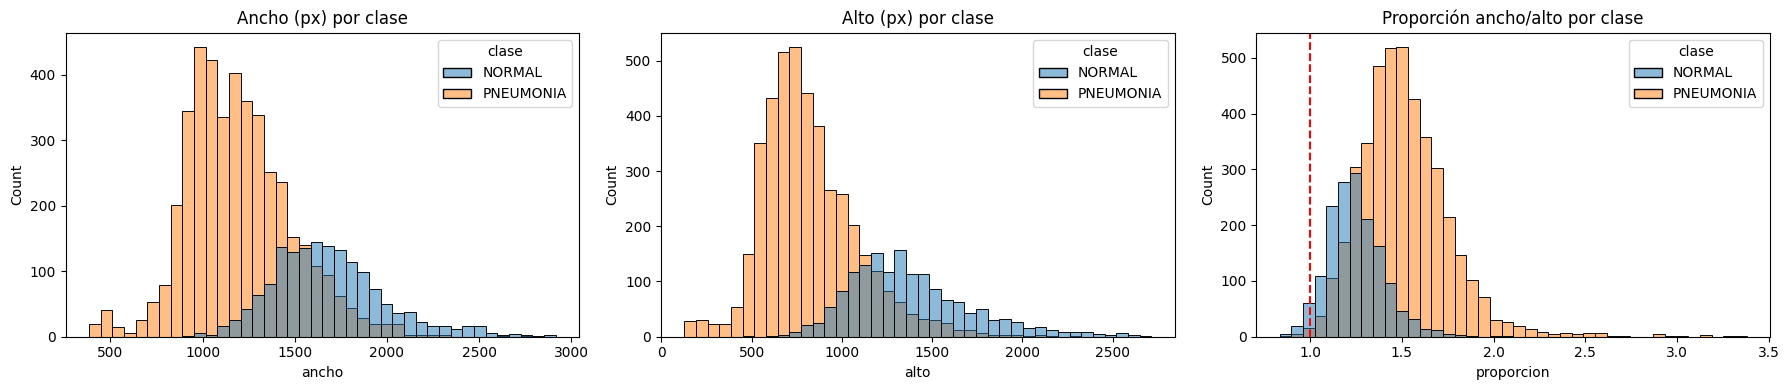

clase  NORMAL  PNEUMONIA
modo                    
L        1583       3990
RGB         0        283

split  test  train  val
modo                   
L       624   4933   16
RGB       0    283    0


In [ ]:
import seaborn as sns

fig, ejes = plt.subplots(1, 3, figsize=(18, 4))

# Histograma del ancho, separado por clase
sns.histplot(data=df, x="ancho", hue="clase", bins=40, ax=ejes[0])
ejes[0].set_title("Ancho (px) por clase")

# Histograma del alto, separado por clase
sns.histplot(data=df, x="alto", hue="clase", bins=40, ax=ejes[1])
ejes[1].set_title("Alto (px) por clase")

# Histograma de la proporción ancho/alto (1.0 = cuadrada)
sns.histplot(data=df, x="proporcion", hue="clase", bins=40, ax=ejes[2])
ejes[2].axvline(1.0, color="red", linestyle="--")
ejes[2].set_title("Proporción ancho/alto por clase")

plt.tight_layout()
plt.show()

# Modo de color por clase: ¿las RGB se concentran en alguna clase o split?
print(pd.crosstab(df["modo"], df["clase"]))
print()
print(pd.crosstab(df["modo"], df["split"]))

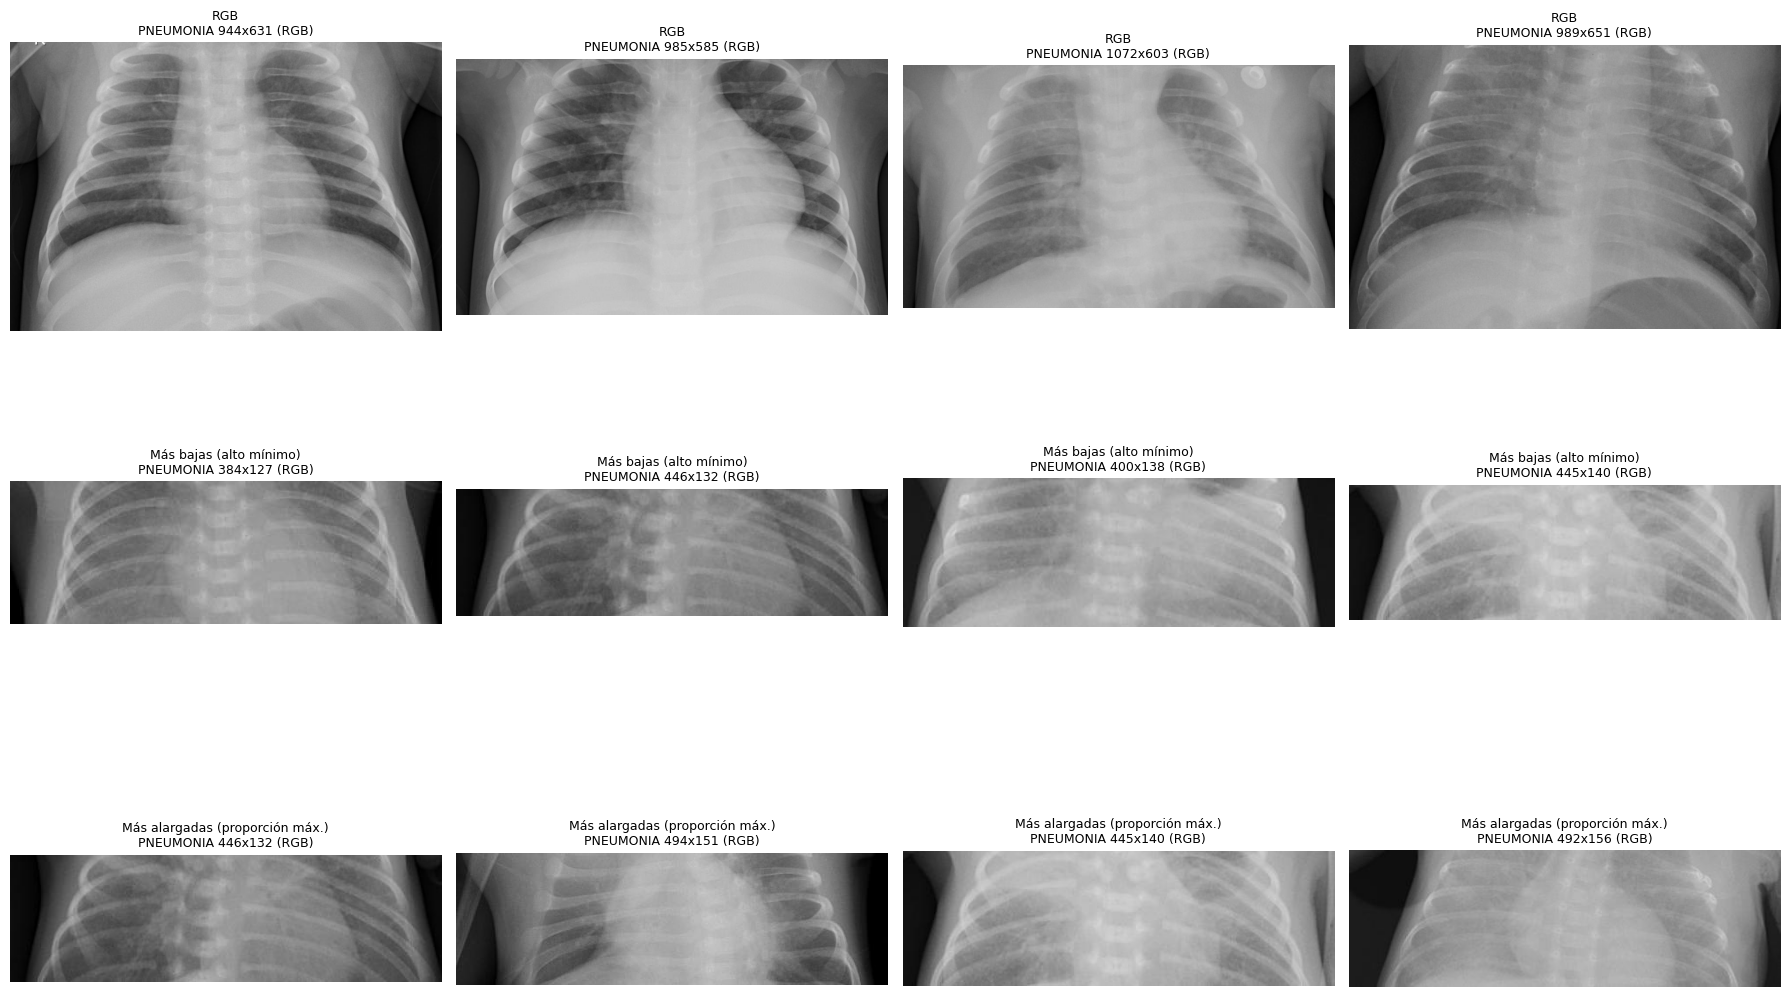

In [ ]:
# Mostrar 4 imágenes RGB, las 4 más pequeñas en alto y las 4 más alargadas
grupos = {
    "RGB": df[df["modo"] == "RGB"].sample(4, random_state=1),
    "Más bajas (alto mínimo)": df.nsmallest(4, "alto"),
    "Más alargadas (proporción máx.)": df.nlargest(4, "proporcion"),
}

fig, ejes = plt.subplots(3, 4, figsize=(18, 12))
for fila, (titulo, sub) in enumerate(grupos.items()):
    for col, (_, r) in enumerate(sub.iterrows()):
        img = Image.open(r["ruta"])
        ejes[fila, col].imshow(img, cmap="gray")
        ejes[fila, col].set_title(f"{titulo}\n{r['clase']} {r['ancho']}x{r['alto']} ({r['modo']})",
                                  fontsize=9)
        ejes[fila, col].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np

# 1) Verificar que ninguna imagen esté corrupta (verify() no decodifica todo, es rápido)
corruptas = []
for ruta in df["ruta"]:
    try:
        with Image.open(ruta) as img:
            img.verify()
    except Exception as e:
        corruptas.append((ruta, str(e)))
print("Imágenes corruptas:", len(corruptas))

# 2) Comprobar si las RGB son realmente grises: diferencia máxima entre canales
rgb = df[df["modo"] == "RGB"].copy()
dif_max = []
for ruta in rgb["ruta"]:
    arr = np.array(Image.open(ruta)).astype(int)
    dif = max(np.abs(arr[..., 0] - arr[..., 1]).max(),
              np.abs(arr[..., 1] - arr[..., 2]).max())
    dif_max.append(dif)
rgb["dif_canales"] = dif_max
print("\nDiferencia máxima entre canales en las RGB:")
print(rgb["dif_canales"].describe())
print("RGB prácticamente grises (diferencia <= 2):", (rgb["dif_canales"] <= 2).sum(), "de", len(rgb))

# 3) Marcar imágenes anómalas: muy bajas o muy alargadas (umbrales ajustables)
df["anomala"] = (df["alto"] < 300) | (df["proporcion"] > 2.0)
print("\nImágenes anómalas:", df["anomala"].sum())
print(pd.crosstab(df["anomala"], [df["clase"], df["modo"]]))

Imágenes corruptas: 0

Diferencia máxima entre canales en las RGB:
count    283.0
mean       0.0
std        0.0
min        0.0
25%        0.0
50%        0.0
75%        0.0
max        0.0
Name: dif_canales, dtype: float64
RGB prácticamente grises (diferencia <= 2): 283 de 283

Imágenes anómalas: 150
clase   NORMAL PNEUMONIA     
modo         L         L  RGB
anomala                      
False     1581      3930  195
True         2        60   88


In [ ]:
import hashlib

# 1) Duplicados exactos: hash MD5 del contenido del archivo
def md5_archivo(ruta):
    with open(ruta, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()

df["md5"] = df["ruta"].apply(md5_archivo)

# 2) Casi duplicados: hash perceptual (dHash) sobre una versión reducida en gris
def dhash(ruta):
    img = Image.open(ruta)
    img.draft("L", (128, 128))            # acelera la lectura de JPEG
    img = img.convert("L").resize((9, 8), Image.LANCZOS)
    a = np.array(img).astype(int)
    return "".join("1" if x else "0" for x in (a[:, 1:] > a[:, :-1]).flatten())

df["dhash"] = df["ruta"].apply(dhash)

# 3) Resumen de duplicados
for col, nombre in [("md5", "exactos (MD5)"), ("dhash", "casi duplicados (dHash)")]:
    grupos = df.groupby(col).filter(lambda g: len(g) > 1)
    n_grupos = grupos[col].nunique()
    print(f"Duplicados {nombre}: {len(grupos)} imágenes en {n_grupos} grupos")

    # Grupos que mezclan splits (riesgo de fuga de datos) o clases (etiquetas contradictorias)
    mezcla_split = df.groupby(col)["split"].nunique()
    mezcla_clase = df.groupby(col)["clase"].nunique()
    print("  Grupos que cruzan splits:", (mezcla_split > 1).sum())
    print("  Grupos con clases distintas:", (mezcla_clase > 1).sum())

# 4) Ejemplo de los primeros grupos exactos
dup_exactos = df[df.duplicated("md5", keep=False)].sort_values("md5")
display(dup_exactos[["split", "clase", "ancho", "alto", "md5"]].head(10))

Duplicados exactos (MD5): 62 imágenes en 30 grupos
  Grupos que cruzan splits: 0
  Grupos con clases distintas: 0
Duplicados casi duplicados (dHash): 504 imágenes en 215 grupos
  Grupos que cruzan splits: 59
  Grupos con clases distintas: 38


,split,clase,ancho,alto,md5
5315,test,NORMAL,1168,824,05c43c853e8209bf0423f73a6f0a8c58
5281,test,NORMAL,1168,824,05c43c853e8209bf0423f73a6f0a8c58
3326,train,PNEUMONIA,1512,1272,061c1fac2e79c2d435a6d4c1e35894e7
2321,train,PNEUMONIA,1512,1272,061c1fac2e79c2d435a6d4c1e35894e7
4151,train,PNEUMONIA,1480,1208,077fce04eafc798401239d127a84f5f0
2059,train,PNEUMONIA,1480,1208,077fce04eafc798401239d127a84f5f0
3586,train,PNEUMONIA,1600,1176,23cd1cdafc40ad7f67e6d076ffec52ab
4928,train,PNEUMONIA,1600,1176,23cd1cdafc40ad7f67e6d076ffec52ab
3488,train,PNEUMONIA,1312,1112,23d698733d4709babc2bf0b40ea67cf4
2570,train,PNEUMONIA,1312,1112,23d698733d4709babc2bf0b40ea67cf4


Casi duplicados (hash fino): 62 imágenes en 30 grupos
  Grupos que cruzan splits: 0
  Grupos con clases distintas: 0


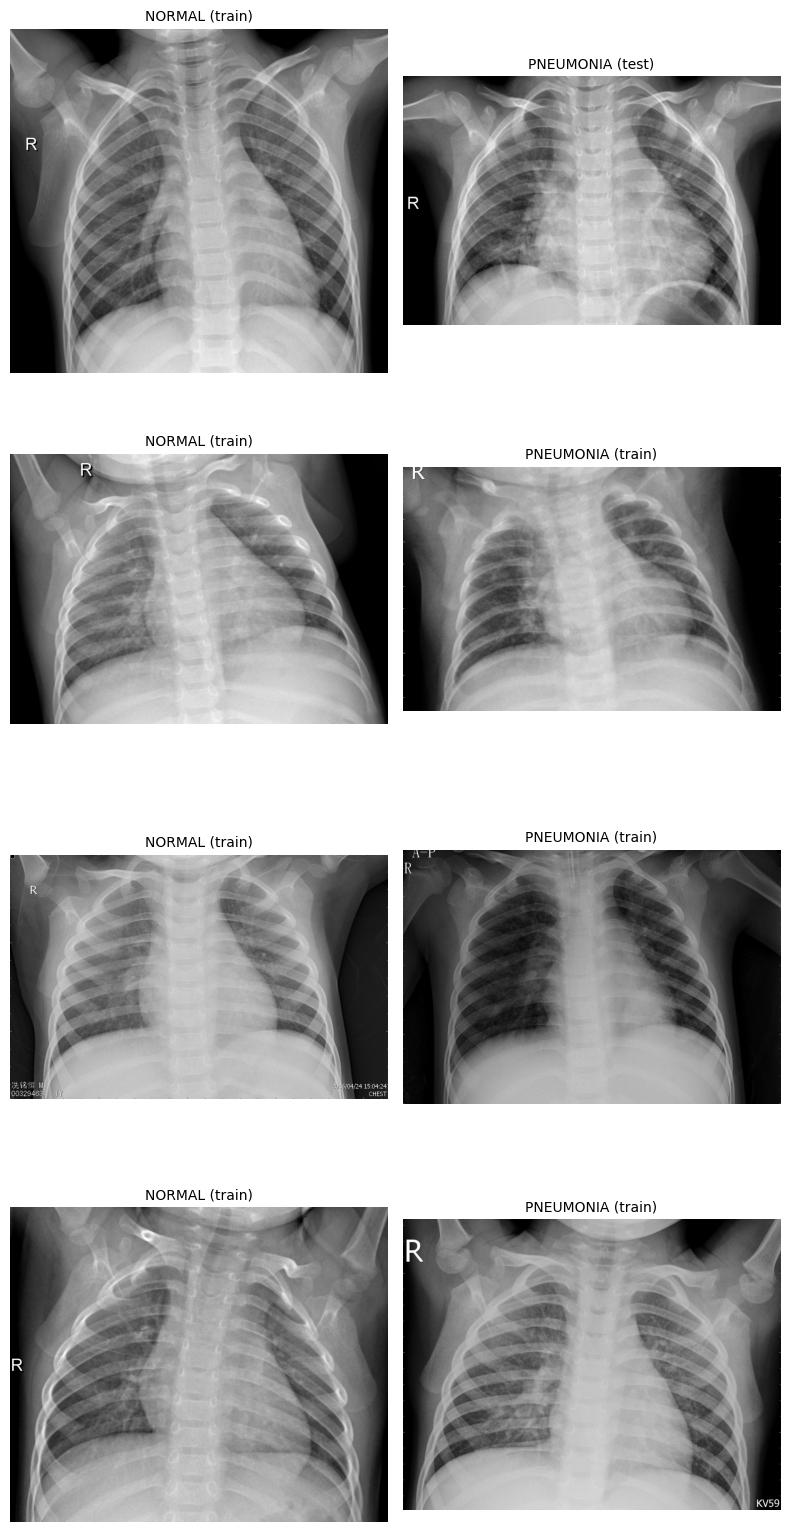

In [ ]:
# Hash perceptual más fino: 16x16 = 256 bits (menos falsos positivos que el de 64 bits)
def dhash_fino(ruta, tam=16):
    img = Image.open(ruta)
    img.draft("L", (256, 256))              # acelera la lectura de JPEG
    img = img.convert("L").resize((tam + 1, tam), Image.LANCZOS)
    a = np.array(img).astype(int)
    return "".join("1" if x else "0" for x in (a[:, 1:] > a[:, :-1]).flatten())

df["dhash_fino"] = df["ruta"].apply(dhash_fino)

# Resumen con el hash fino
grupos = df.groupby("dhash_fino").filter(lambda g: len(g) > 1)
print(f"Casi duplicados (hash fino): {len(grupos)} imágenes en {grupos['dhash_fino'].nunique()} grupos")
print("  Grupos que cruzan splits:", (df.groupby("dhash_fino")["split"].nunique() > 1).sum())
print("  Grupos con clases distintas:", (df.groupby("dhash_fino")["clase"].nunique() > 1).sum())

# Ver 4 grupos del hash grueso que mezclaban NORMAL y PNEUMONIA (probables falsos positivos)
mezcla = df.groupby("dhash")["clase"].nunique()
hashes_mezcla = mezcla[mezcla > 1].index[:4]

fig, ejes = plt.subplots(4, 2, figsize=(8, 16))
for fila, h in enumerate(hashes_mezcla):
    g = df[df["dhash"] == h]
    par = pd.concat([g[g["clase"] == "NORMAL"].head(1), g[g["clase"] == "PNEUMONIA"].head(1)])
    for col, (_, r) in enumerate(par.iterrows()):
        ejes[fila, col].imshow(Image.open(r["ruta"]), cmap="gray")
        ejes[fila, col].set_title(f"{r['clase']} ({r['split']})", fontsize=10)
        ejes[fila, col].axis("off")
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split

# Interruptor: poner False si el equipo decide conservar las 150 imágenes anómalas
EXCLUIR_ANOMALAS = True

df_limpio = df.copy()
print("Imágenes iniciales:", len(df_limpio))

# 1) Eliminar duplicados exactos (se conserva una imagen por grupo MD5)
df_limpio = df_limpio.drop_duplicates(subset="md5", keep="first")
print("Tras quitar duplicados exactos:", len(df_limpio))

# 2) Excluir imágenes anómalas (muy bajas o muy alargadas)
if EXCLUIR_ANOMALAS:
    df_limpio = df_limpio[~df_limpio["anomala"]]
print("Tras quitar anómalas:", len(df_limpio))

# 3) Nuevo split estratificado por clase: 70 % train, 15 % val, 15 % test
df_train, df_resto = train_test_split(
    df_limpio, test_size=0.30, stratify=df_limpio["clase"], random_state=42)
df_val, df_test = train_test_split(
    df_resto, test_size=0.50, stratify=df_resto["clase"], random_state=42)

df_train = df_train.assign(split_nuevo="train")
df_val = df_val.assign(split_nuevo="val")
df_test = df_test.assign(split_nuevo="test")
df_limpio = pd.concat([df_train, df_val, df_test]).reset_index(drop=True)

# 4) Verificar que el balance entre clases se mantiene igual en los tres splits
conteo_nuevo = pd.crosstab(df_limpio["split_nuevo"], df_limpio["clase"], margins=True)
print("\nConteo con el split nuevo:")
print(conteo_nuevo)
print("\nPorcentaje de neumonía por split:")
print((conteo_nuevo["PNEUMONIA"] / conteo_nuevo["All"] * 100).round(1))

# 5) Nombres de archivo de ejemplo (para revisar si traen el identificador del paciente)
print("\nEjemplos de nombres de archivo:")
for c in ["NORMAL", "PNEUMONIA"]:
    print(c, df_limpio[df_limpio["clase"] == c]["ruta"].head(3).apply(os.path.basename).tolist())


Imágenes iniciales: 5856
Tras quitar duplicados exactos: 5824
Tras quitar anómalas: 5674

Conteo con el split nuevo:
clase        NORMAL  PNEUMONIA   All
split_nuevo                         
test            237        615   852
train          1104       2867  3971
val             236        615   851
All            1577       4097  5674

Porcentaje de neumonía por split:
split_nuevo
test     72.2
train    72.2
val      72.3
All      72.2
dtype: float64

Ejemplos de nombres de archivo:
NORMAL ['NORMAL2-IM-1047-0001.jpeg', 'NORMAL2-IM-0229-0001.jpeg', 'NORMAL2-IM-1258-0001-0002.jpeg']
PNEUMONIA ['person127_bacteria_603.jpeg', 'person1649_bacteria_4379.jpeg', 'person113_bacteria_542.jpeg']


In [ ]:
import re
from sklearn.model_selection import StratifiedGroupKFold

# 1) Extraer el identificador de paciente desde el nombre del archivo
def id_paciente(fila):
    nombre = os.path.basename(fila["ruta"])
    patron = r"person(\d+)" if fila["clase"] == "PNEUMONIA" else r"IM-(\d+)"
    m = re.search(patron, nombre)
    # Si un nombre no coincide, se trata como paciente propio (no se agrupa)
    return f"{fila['clase']}_{m.group(1)}" if m else f"{fila['clase']}_{nombre}"

df_limpio["paciente"] = df_limpio.apply(id_paciente, axis=1)

# 2) Cuántos pacientes hay y cuántas imágenes tiene cada uno
por_paciente = df_limpio.groupby("paciente").size()
print("Pacientes únicos:", df_limpio["paciente"].nunique())
print(df_limpio.groupby("clase")["paciente"].nunique())
print("\nImágenes por paciente:")
print(por_paciente.describe())

# 3) Split por paciente, estratificado por clase (7 partes: 1 para test, 1 para val, 5 para train)
sgkf = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=42)
partes = list(sgkf.split(df_limpio, df_limpio["clase"], groups=df_limpio["paciente"]))

df_limpio["split_nuevo"] = "train"
df_limpio.loc[partes[0][1], "split_nuevo"] = "test"
df_limpio.loc[partes[1][1], "split_nuevo"] = "val"

# 4) Verificar que ningún paciente aparezca en dos splits (sin fuga de datos)
pac = {s: set(df_limpio.loc[df_limpio["split_nuevo"] == s, "paciente"])
       for s in ["train", "val", "test"]}
print("\nPacientes compartidos train-val:", len(pac["train"] & pac["val"]))
print("Pacientes compartidos train-test:", len(pac["train"] & pac["test"]))
print("Pacientes compartidos val-test:", len(pac["val"] & pac["test"]))

# 5) Conteo y balance por split
conteo_nuevo = pd.crosstab(df_limpio["split_nuevo"], df_limpio["clase"], margins=True)
print("\nConteo con el split por paciente:")
print(conteo_nuevo)
print("\nPorcentaje de neumonía por split:")
print((conteo_nuevo["PNEUMONIA"] / conteo_nuevo["All"] * 100).round(1))

Pacientes únicos: 2755
clase
NORMAL       1115
PNEUMONIA    1640
Name: paciente, dtype: int64

Imágenes por paciente:
count    2755.000000
mean        2.059528
std         1.770844
min         1.000000
25%         1.000000
50%         2.000000
75%         2.000000
max        31.000000
dtype: float64

Pacientes compartidos train-val: 0
Pacientes compartidos train-test: 0
Pacientes compartidos val-test: 0

Conteo con el split por paciente:
clase        NORMAL  PNEUMONIA   All
split_nuevo                         
test            215        641   856
train          1132       2904  4036
val             230        552   782
All            1577       4097  5674

Porcentaje de neumonía por split:
split_nuevo
test     74.9
train    72.0
val      70.6
All      72.2
dtype: float64


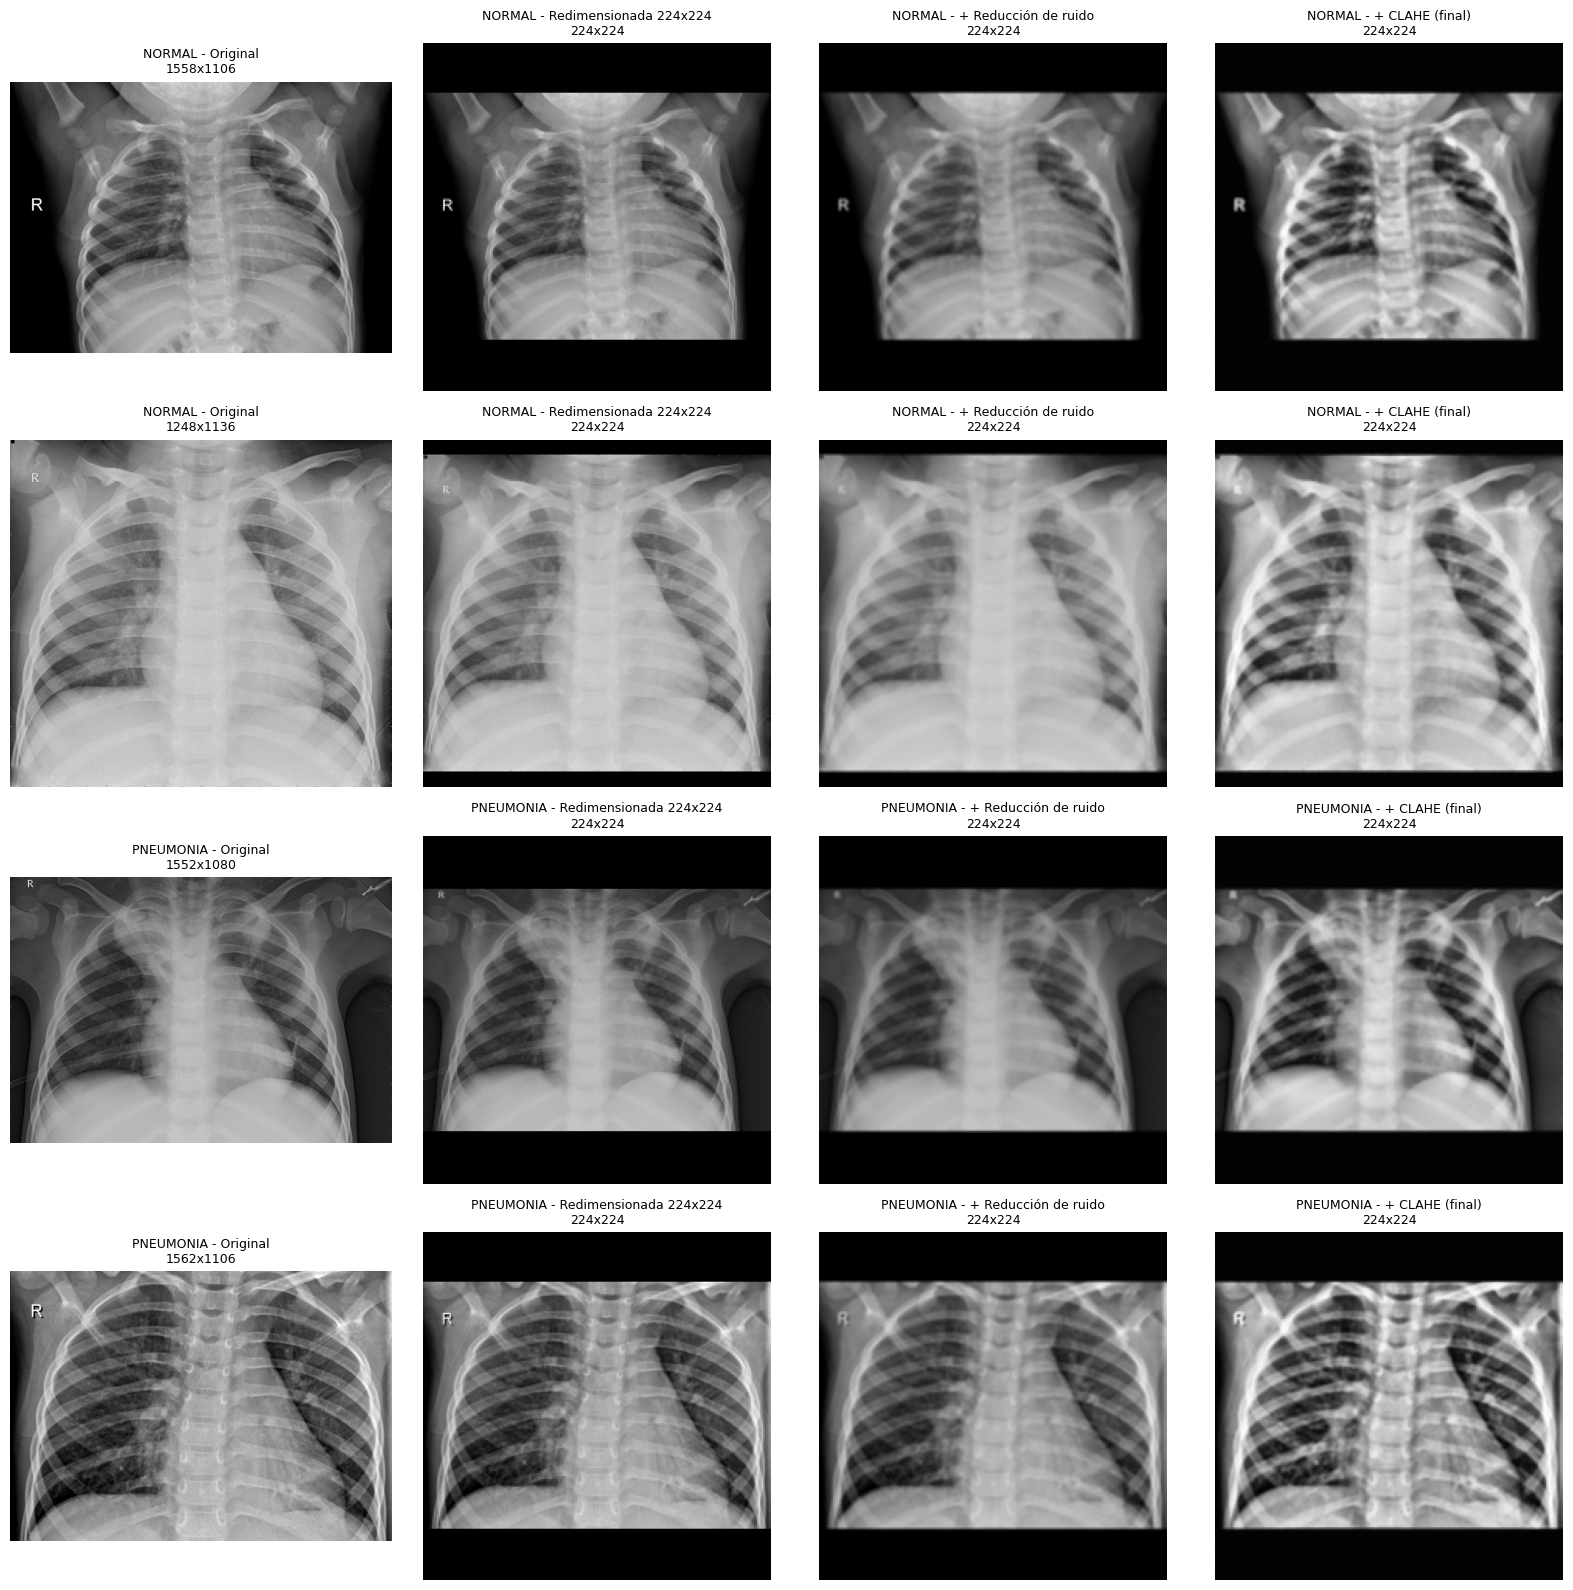

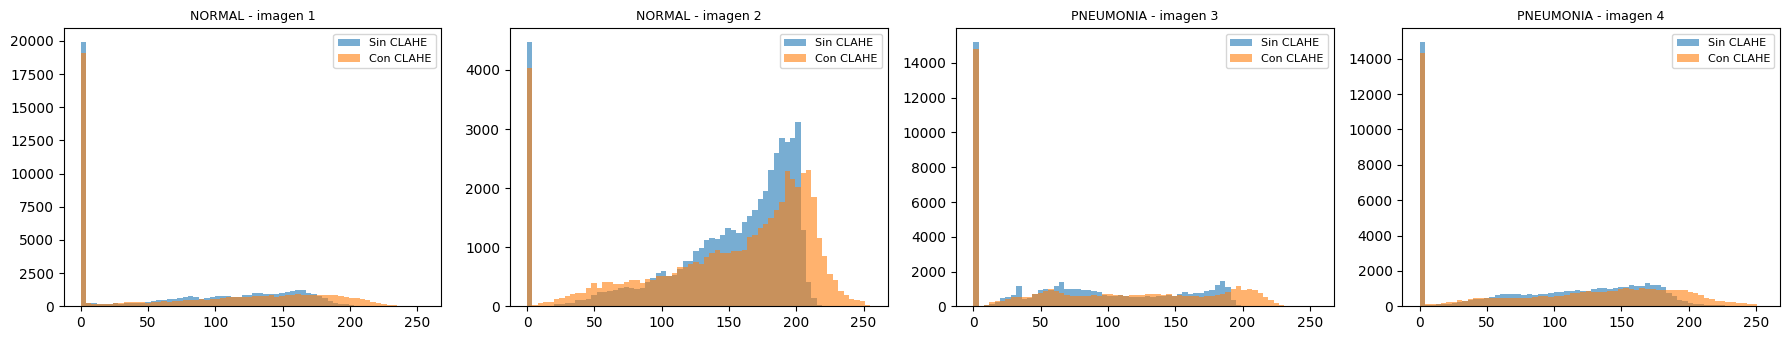

In [ ]:
import cv2

TAM = 224  # tamaño objetivo (alto y ancho)

# 1) Leer siempre en un solo canal (unifica las 283 imágenes que estaban en RGB)
def leer_gris(ruta):
    return cv2.imread(ruta, cv2.IMREAD_GRAYSCALE)

# 2) Redimensionar conservando la proporción y rellenar con negro hasta TAM x TAM
def redimensionar_con_relleno(img, tam=TAM):
    h, w = img.shape
    escala = tam / max(h, w)
    nuevo_w, nuevo_h = int(round(w * escala)), int(round(h * escala))
    reducida = cv2.resize(img, (nuevo_w, nuevo_h), interpolation=cv2.INTER_AREA)
    lienzo = np.zeros((tam, tam), dtype=np.uint8)
    y0, x0 = (tam - nuevo_h) // 2, (tam - nuevo_w) // 2
    lienzo[y0:y0 + nuevo_h, x0:x0 + nuevo_w] = reducida
    return lienzo

# 3) Reducción de ruido suave (filtro gaussiano 3x3)
def reducir_ruido(img):
    return cv2.GaussianBlur(img, (3, 3), 0)

# 4) CLAHE: ecualización adaptativa de contraste por zonas
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))

# Elegir 2 imágenes de cada clase del split de entrenamiento
muestras = pd.concat([
    df_limpio[(df_limpio["split_nuevo"] == "train") & (df_limpio["clase"] == c)].sample(2, random_state=3)
    for c in ["NORMAL", "PNEUMONIA"]
])

titulos = ["Original", "Redimensionada 224x224", "+ Reducción de ruido", "+ CLAHE (final)"]
fig, ejes = plt.subplots(4, 4, figsize=(16, 16))
finales = []

for fila, (_, r) in enumerate(muestras.iterrows()):
    original = leer_gris(r["ruta"])
    redim = redimensionar_con_relleno(original)
    suave = reducir_ruido(redim)
    final = clahe.apply(suave)
    finales.append((redim, final))

    for col, im in enumerate([original, redim, suave, final]):
        ejes[fila, col].imshow(im, cmap="gray", vmin=0, vmax=255)
        ejes[fila, col].set_title(f"{r['clase']} - {titulos[col]}\n{im.shape[1]}x{im.shape[0]}", fontsize=9)
        ejes[fila, col].axis("off")

plt.tight_layout()
plt.show()

# 5) Histogramas de intensidad antes y después de CLAHE (para justificar el contraste)
fig, ejes = plt.subplots(1, 4, figsize=(18, 3.5))
for k, (redim, final) in enumerate(finales):
    ejes[k].hist(redim.ravel(), bins=64, range=(0, 255), alpha=0.6, label="Sin CLAHE")
    ejes[k].hist(final.ravel(), bins=64, range=(0, 255), alpha=0.6, label="Con CLAHE")
    ejes[k].set_title(f"{muestras.iloc[k]['clase']} - imagen {k + 1}", fontsize=9)
    ejes[k].legend(fontsize=8)
plt.tight_layout()
plt.show()


In [ ]:
from tqdm.auto import tqdm

SALIDA = "/content/dataset_preprocesado"

def preprocesar(ruta, tam=TAM):
    """Pipeline completo: gris -> 224x224 con relleno -> suavizado -> CLAHE."""
    img = leer_gris(ruta)
    img = redimensionar_con_relleno(img, tam)
    img = reducir_ruido(img)
    return clahe.apply(img)

# Nombre de salida: mismo nombre, extension PNG (sin perdida). Verificar que no haya choques.
df_limpio["archivo"] = df_limpio["ruta"].apply(lambda r: os.path.splitext(os.path.basename(r))[0] + ".png")
assert not df_limpio.duplicated(["split_nuevo", "clase", "archivo"]).any(), "Nombres repetidos"

rutas_proc = []
for r in tqdm(df_limpio.itertuples(), total=len(df_limpio)):
    carpeta = os.path.join(SALIDA, r.split_nuevo, r.clase)
    os.makedirs(carpeta, exist_ok=True)
    destino = os.path.join(carpeta, r.archivo)
    cv2.imwrite(destino, preprocesar(r.ruta))
    rutas_proc.append(os.path.relpath(destino, SALIDA))

df_limpio["ruta_procesada"] = rutas_proc

# Manifiesto: lo unico que hay que subir al repositorio (las imagenes se regeneran con el cuaderno)
manifiesto = df_limpio[["split_nuevo", "clase", "paciente", "ancho", "alto", "ruta_procesada"]]
manifiesto.to_csv(os.path.join(SALIDA, "manifiesto.csv"), index=False)
print("Imagenes procesadas:", len(manifiesto))
print(pd.crosstab(manifiesto["split_nuevo"], manifiesto["clase"], margins=True))

  0%|          | 0/5674 [00:00<?, ?it/s]

Imagenes procesadas: 5674
clase        NORMAL  PNEUMONIA   All
split_nuevo                         
test            215        641   856
train          1132       2904  4036
val             230        552   782
All            1577       4097  5674


Archivos en disco: 5674 | filas en manifiesto: 5674


  0%|          | 0/5674 [00:00<?, ?it/s]

OK: todas son (224, 224) uint8, un canal


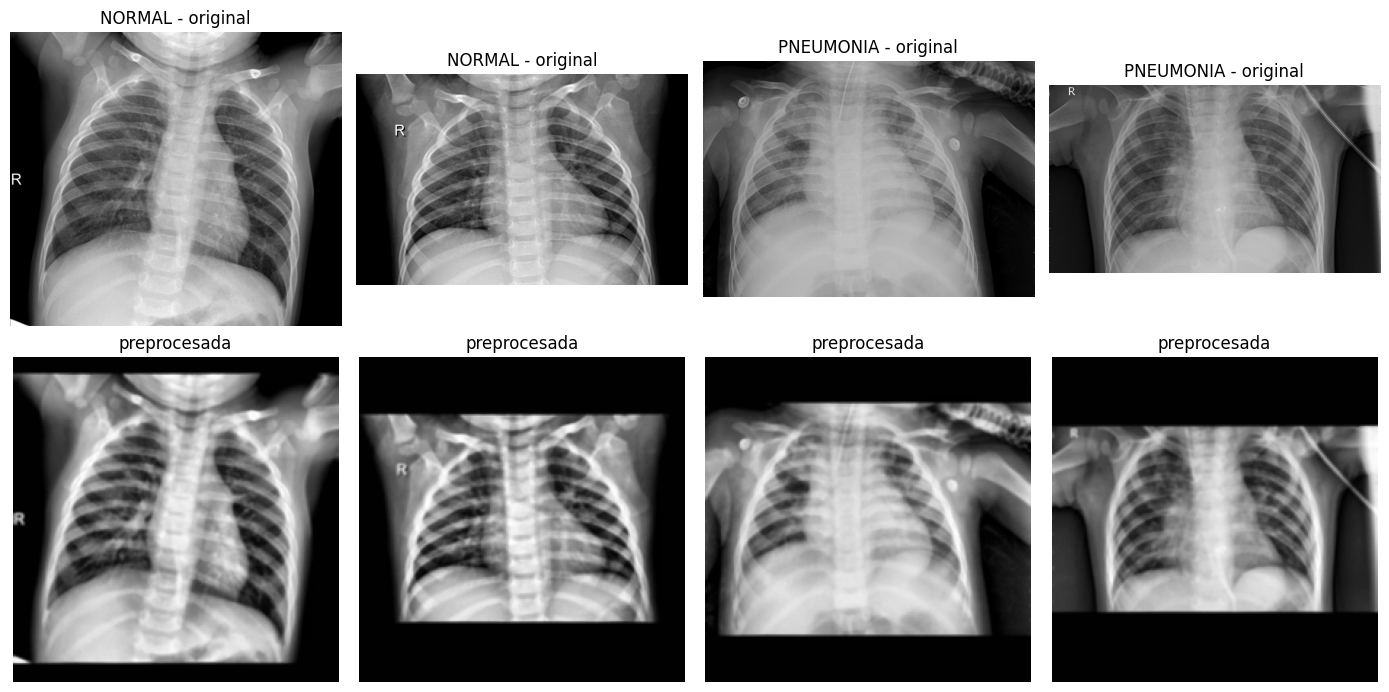

In [ ]:
# 1) Los archivos en disco coinciden con el manifiesto
en_disco = sum(len(f) for _, _, f in os.walk(SALIDA) if f) - 1   # -1 por manifiesto.csv
print("Archivos en disco:", en_disco, "| filas en manifiesto:", len(manifiesto))
assert en_disco == len(manifiesto)

# 2) Todas las imagenes: 224x224, 1 canal, uint8
for rel in tqdm(manifiesto["ruta_procesada"]):
    im = cv2.imread(os.path.join(SALIDA, rel), cv2.IMREAD_UNCHANGED)
    assert im is not None and im.shape == (TAM, TAM) and im.dtype == np.uint8, rel
print("OK: todas son", (TAM, TAM), "uint8, un canal")

# 3) Antes vs despues en 4 imagenes de entrenamiento (2 por clase)
ej = pd.concat([df_limpio[(df_limpio["split_nuevo"] == "train") & (df_limpio["clase"] == c)].sample(2, random_state=7)
                for c in ["NORMAL", "PNEUMONIA"]])
fig, ejes = plt.subplots(2, 4, figsize=(14, 7))
for k, (_, r) in enumerate(ej.iterrows()):
    ejes[0, k].imshow(leer_gris(r["ruta"]), cmap="gray"); ejes[0, k].set_title(f"{r['clase']} - original")
    ejes[1, k].imshow(cv2.imread(os.path.join(SALIDA, r["ruta_procesada"]), 0), cmap="gray"); ejes[1, k].set_title("preprocesada")
    ejes[0, k].axis("off"); ejes[1, k].axis("off")
plt.tight_layout(); plt.show()

In [ ]:
# Media y desviacion estandar del conjunto de entrenamiento (acumulado, sin cargar todo en memoria)
tr = manifiesto[manifiesto["split_nuevo"] == "train"]
suma, suma_cuad, n_pix = 0.0, 0.0, 0
for rel in tqdm(tr["ruta_procesada"]):
    x = cv2.imread(os.path.join(SALIDA, rel), cv2.IMREAD_GRAYSCALE).astype(np.float64) / 255.0
    suma += x.sum(); suma_cuad += (x ** 2).sum(); n_pix += x.size
MEDIA = float(suma / n_pix)
STD = float(np.sqrt(suma_cuad / n_pix - MEDIA ** 2))
print(f"Media (train): {MEDIA:.4f} | Desviacion estandar (train): {STD:.4f}")

# Pesos de clase para compensar el desbalance (n_total / (n_clases * n_clase))
conteo_tr = tr["clase"].value_counts()
PESOS_CLASE = {c: float(len(tr) / (2 * conteo_tr[c])) for c in ["NORMAL", "PNEUMONIA"]}
print("Pesos de clase:", {c: round(p, 3) for c, p in PESOS_CLASE.items()})

# Etiquetas: NORMAL = 0, PNEUMONIA = 1
ETIQUETAS = {"NORMAL": 0, "PNEUMONIA": 1}

def cargar_split(split):
    """Devuelve X (N, 224, 224, 1) float32 normalizado e y (N,) int, listo para el modelo."""
    sub = manifiesto[manifiesto["split_nuevo"] == split]
    X = np.stack([cv2.imread(os.path.join(SALIDA, rel), cv2.IMREAD_GRAYSCALE) for rel in sub["ruta_procesada"]])
    X = ((X.astype(np.float32) / 255.0) - np.float32(MEDIA)) / np.float32(STD)
    y = sub["clase"].map(ETIQUETAS).to_numpy()
    return X[..., None], y

# Prueba rapida con el split de validacion
X_val, y_val = cargar_split("val")
print("X_val:", X_val.shape, X_val.dtype, "| y_val:", y_val.shape, "| neumonia:", y_val.mean().round(3))

  0%|          | 0/4036 [00:00<?, ?it/s]

Media (train): 0.3793 | Desviacion estandar (train): 0.3104
Pesos de clase: {'NORMAL': 1.783, 'PNEUMONIA': 0.695}
X_val: (782, 224, 224, 1) float32 | y_val: (782,) | neumonia: 0.706


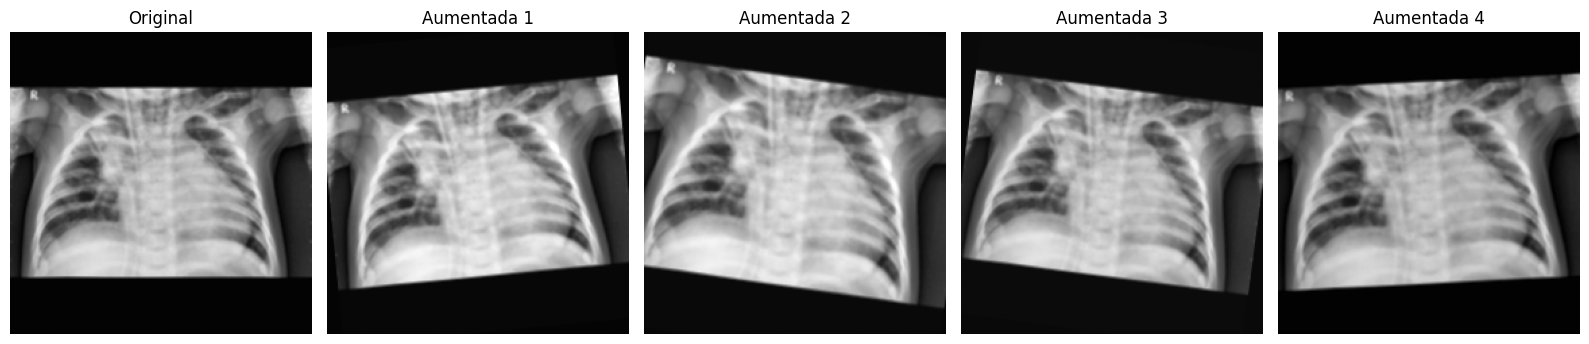

In [ ]:
def augmentar(img, rng):
    """Rotacion (+-10 grados), zoom (0.9-1.1) y brillo/contraste leves. Solo se aplica a train."""
    h, w = img.shape
    M = cv2.getRotationMatrix2D((w / 2, h / 2), rng.uniform(-10, 10), rng.uniform(0.9, 1.1))
    out = cv2.warpAffine(img, M, (w, h), flags=cv2.INTER_LINEAR, borderValue=0)
    return cv2.convertScaleAbs(out, alpha=rng.uniform(0.9, 1.1), beta=rng.uniform(-10, 10))

rng = np.random.default_rng(42)
rel = tr[tr["clase"] == "PNEUMONIA"]["ruta_procesada"].iloc[0]
base = cv2.imread(os.path.join(SALIDA, rel), cv2.IMREAD_GRAYSCALE)

fig, ejes = plt.subplots(1, 5, figsize=(16, 3.5))
ejes[0].imshow(base, cmap="gray", vmin=0, vmax=255); ejes[0].set_title("Original")
for k in range(1, 5):
    ejes[k].imshow(augmentar(base, rng), cmap="gray", vmin=0, vmax=255); ejes[k].set_title(f"Aumentada {k}")
for e in ejes: e.axis("off")
plt.tight_layout(); plt.show()